# 01 · First look at the TMDB pull

Day 1 check: is the raw pull (`data/raw/tmdb_movies.jsonl`) good enough to start cleaning on Day 2?

1. Pull completeness
2. Coverage by decade (budget, revenue, director, certification)
3. Split sizes (train ≤2015, validation 2016–18, test 2019+)
4. Plots: budget vs revenue, score distribution, languages
5. Suspicious values (placeholder money, absurd ratios, local-currency budgets)
6. Key numbers → `data/day1_summary.json`

Nothing here changes the data; the cleaning rules are decided on Day 2 using these numbers.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
SUMMARY_PATH = ROOT / "data" / "day1_summary.json"

In [2]:
def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        # skip a half-written last line, in case a pull is still running
        return [json.loads(line) for line in f if line.endswith("\n")]


raw = load_jsonl(RAW_DIR / "tmdb_movies.jsonl")


def crew_names(movie, job):
    return [c["name"] for c in movie["crew"] if c["job"] == job]


df = pd.DataFrame(
    {
        "id": m["id"],
        "title": m["title"],
        "original_language": m["original_language"],
        "release_date": m["release_date"],
        "status": m["status"],
        "runtime": m["runtime"],
        "budget": m["budget"],
        "revenue": m["revenue"],
        "vote_count": m["vote_count"],
        "vote_average": m["vote_average"],
        "us_certification": m["us_certification"],
        "director": ", ".join(crew_names(m, "Director")) or None,
        "n_cast": len(m["cast"]),
        "n_keywords": len(m["keywords"]),
        "has_collection": m["collection"] is not None,
        "has_overview": bool((m["overview"] or "").strip()),
        "has_poster": bool(m["poster_path"]),
    }
    for m in raw
)
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year.astype("Int64")
df["decade"] = (df["year"] // 10 * 10).astype("Int64")
df["has_budget"] = df["budget"] > 0
df["has_revenue"] = df["revenue"] > 0
df["has_money"] = df["has_budget"] & df["has_revenue"]
df["has_director"] = df["director"].notna()
df["has_cert"] = df["us_certification"].notna()

print(f"{len(df):,} films loaded")
df.head()

79,199 films loaded


,id,title,original_language,release_date,status,runtime,budget,revenue,vote_count,vote_average,us_certification,director,n_cast,n_keywords,has_collection,has_overview,has_poster,year,decade,has_budget,has_revenue,has_money,has_director,has_cert
0,475557,Joker,en,2019-10-01,Released,122,55000000,1078958629,28543,8.114,R,Todd Phillips,15,18,True,True,True,2019,2010,True,True,True,True,True
1,496243,Parasite,ko,2019-05-30,Released,133,11363000,257591776,21525,8.491,R,Bong Joon Ho,15,15,False,True,True,2019,2010,True,True,True,True,True
2,299534,Avengers: Endgame,en,2019-04-24,Released,181,356000000,2938567784,29056,8.246,PG-13,"Joe Russo, Anthony Russo",15,13,True,True,True,2019,2010,True,True,True,True,True
3,429617,Spider-Man: Far From Home,en,2019-06-28,Released,129,160000000,1132723226,17774,7.388,PG-13,Jon Watts,15,15,True,True,True,2019,2010,True,True,True,True,True
4,466272,Once Upon a Time... in Hollywood,en,2019-07-24,Released,162,95000000,393869691,15428,7.417,R,Quentin Tarantino,15,25,True,True,True,2019,2010,True,True,True,True,True


## 1 · Pull completeness

In [3]:
discovered = pd.read_csv(RAW_DIR / "discover_ids.csv")
missing_path = RAW_DIR / "missing_ids.txt"
missing_ids = set(map(int, missing_path.read_text().split())) if missing_path.exists() else set()

n_discovered = discovered["id"].nunique()
not_fetched = set(discovered["id"]) - set(df["id"]) - missing_ids

completeness = {
    "discovered": n_discovered,
    "saved": len(df),
    "missing_404": len(missing_ids),
    "not_fetched": len(not_fetched),
    "duplicate_ids_in_file": int(df["id"].duplicated().sum()),
    "no_release_date": int(df["release_date"].isna().sum()),
}
print(completeness)
print("\nStatus:", df["status"].value_counts().to_dict())

per_year = discovered.groupby("year")["id"].nunique()
print(f"\nFilms discovered per year: min {per_year.min()} ({per_year.idxmin()}), max {per_year.max()}")
per_year[per_year < per_year.max()]

{'discovered': 79198, 'saved': 79199, 'missing_404': 0, 'not_fetched': 0, 'duplicate_ids_in_file': 0, 'no_release_date': 0}

Status: {'Released': 79199}

Films discovered per year: min 1199 (2005), max 1200


year
2005    1199
2025    1199
Name: id, dtype: int64

In [4]:
# Discover year (primary release year) vs the release_date TMDB gives on the details page
year_check =discovered.drop_duplicates("id")[["id", "year"]].rename(columns={"year": "discover_year"}).merge(
    df[["id", "year"]], on="id"
)
print(f"Films whose details release year differs from the discover year: {(year_check['discover_year'] != year_check['year']).sum():,}")

Films whose details release year differs from the discover year: 0


## 2 · Coverage by decade

In [5]:
coverage_cols = {
    "has_budget": "budget",
    "has_revenue": "revenue",
    "has_money": "budget & revenue",
    "has_director": "director",
    "has_cert": "US cert",
    "has_overview": "overview",
}
by_decade = df.groupby("decade").agg(films=("id", "size"), **{v: (k, "mean") for k, v in coverage_cols.items()})
by_decade["keywords (≥1)"] = df.assign(k=df["n_keywords"] > 0).groupby("decade")["k"].mean()
pct_cols = by_decade.columns.drop("films")
by_decade.style.format({c: "{:.0%}" for c in pct_cols} | {"films": "{:,}"})

,films,budget,revenue,budget & revenue,director,US cert,overview,keywords (≥1)
decade,,,,,,,,
1960,"12,000",5%,4%,2%,99%,14%,97%,57%
1970,"12,000",7%,5%,4%,100%,24%,99%,62%
1980,"12,000",12%,14%,9%,100%,28%,99%,64%
1990,"12,000",18%,19%,14%,100%,37%,99%,68%
2000,"11,999",32%,32%,23%,100%,45%,100%,76%
2010,"12,000",34%,39%,25%,100%,52%,100%,83%
2020,"7,200",23%,33%,17%,100%,54%,100%,78%


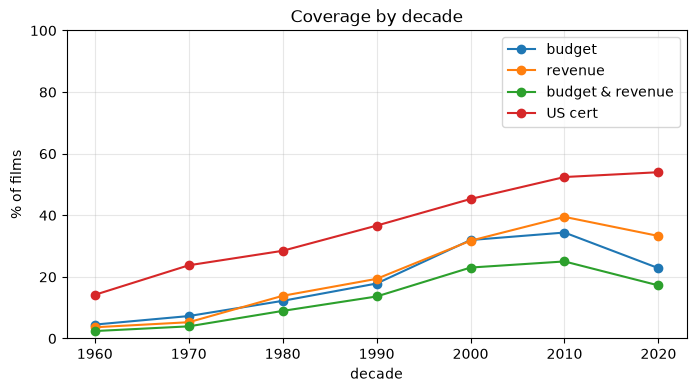

In [6]:
ax = (by_decade[["budget", "revenue", "budget & revenue", "US cert"]] * 100).plot(marker="o", figsize=(8, 4))
ax.set(title="Coverage by decade", xlabel="decade", ylabel="% of films", ylim=(0, 100))
ax.grid(alpha=0.3)
plt.show()

## 3 · Split sizes

In [7]:
def split_of(year):
    if pd.isna(year):
        return "unknown"
    return "train (≤2015)" if year <= 2015 else "validation (2016–18)" if year <= 2018 else "test (2019+)"


df["split"] = df["year"].map(split_of)
split_order = ["train (≤2015)", "validation (2016–18)", "test (2019+)"]

splits = pd.DataFrame(
    {
        "all films": df["split"].value_counts(),
        "budget & revenue": df[df["has_money"]]["split"].value_counts(),
        "budget": df[df["has_budget"]]["split"].value_counts(),
        "votes ≥ 10": df[df["vote_count"] >= 10]["split"].value_counts(),
        "votes ≥ 50": df[df["vote_count"] >= 50]["split"].value_counts(),
        "votes ≥ 100": df[df["vote_count"] >= 100]["split"].value_counts(),
    }
).reindex(split_order).fillna(0).astype(int)
splits

,all films,budget & revenue,budget,votes ≥ 10,votes ≥ 50,votes ≥ 100
split,,,,,,
train (≤2015),67199,8092,11486,48264,22016,14453
validation (2016–18),3600,889,1168,3600,3600,2789
test (2019+),8400,1501,1979,8400,7461,4921


The vote threshold for the score target is set on Day 2; the three columns above show what 10, 50 or 100 would cost.

## 4 · Plots

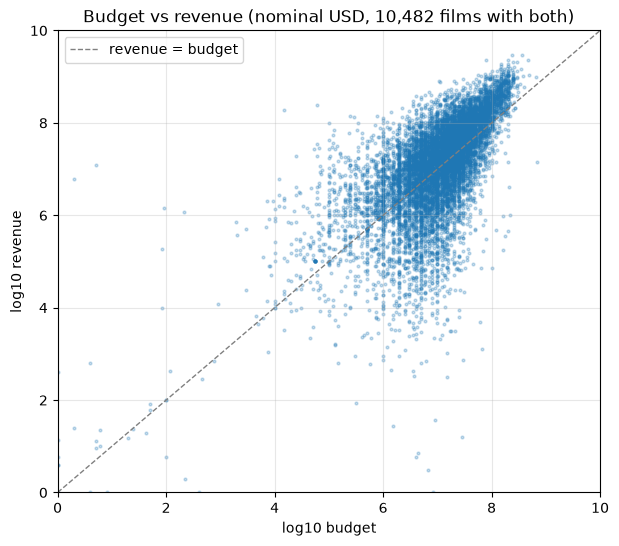

In [8]:
money = df[df["has_money"]]
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(np.log10(money["budget"]), np.log10(money["revenue"]), s=4, alpha=0.25)
lims = [0, 10]
ax.plot(lims, lims, color="grey", lw=1, ls="--", label="revenue = budget")
ax.set(
    title=f"Budget vs revenue (nominal USD, {len(money):,} films with both)",
    xlabel="log10 budget", ylabel="log10 revenue", xlim=lims, ylim=lims,
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Points in the bottom-left corner (log10 < 3, i.e. under $1,000) are the placeholder values Day 2 will null out.

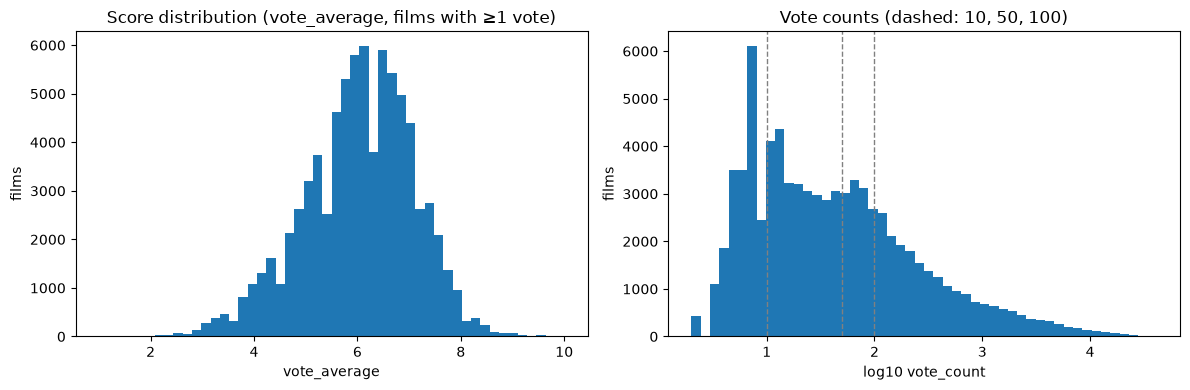

In [9]:
voted = df[df["vote_count"] > 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(voted["vote_average"], bins=50)
axes[0].set(title="Score distribution (vote_average, films with ≥1 vote)", xlabel="vote_average", ylabel="films")
axes[1].hist(np.log10(voted["vote_count"]), bins=50)
for t in (10, 50, 100):
    axes[1].axvline(np.log10(t), color="grey", ls="--", lw=1)
axes[1].set(title="Vote counts (dashed: 10, 50, 100)", xlabel="log10 vote_count", ylabel="films")
plt.tight_layout()
plt.show()

In [10]:
# Score noise vs vote count: low-vote scores spread much wider
bins = pd.cut(voted["vote_count"], [0, 10, 50, 100, 500, 1000, np.inf], right=False)
voted.groupby(bins, observed=True)["vote_average"].describe()[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
vote_count,,,,,
"[0.0, 10.0)",18935.0,5.779097,1.220492,1.000,10.000
"[10.0, 50.0)",27187.0,5.812481,1.067324,1.700,10.000
"[50.0, 100.0)",10914.0,6.123342,0.942153,1.600,9.100
"[100.0, 500.0)",14281.0,6.315951,0.844496,1.825,9.900
"[500.0, 1000.0)",3009.0,6.528712,0.764402,3.339,8.442
"[1000.0, inf)",4873.0,6.763735,0.732326,2.934,8.805


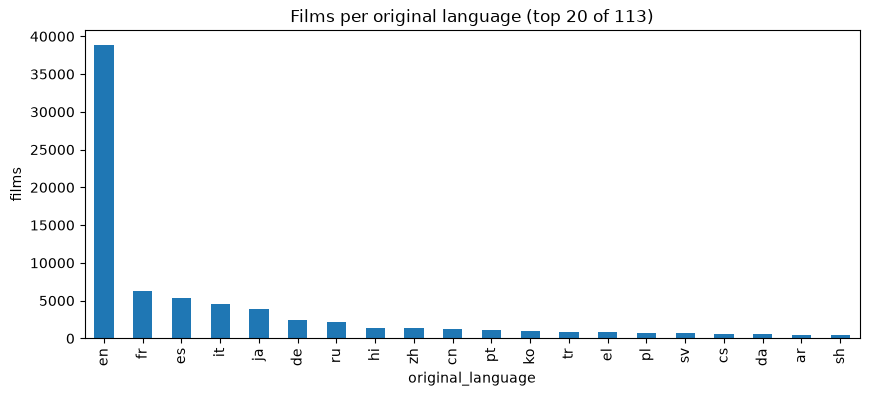

,films,budget,revenue,both
original_language,,,,
en,"38,845",29%,29%,21%
fr,"6,325",12%,14%,7%
es,"5,328",6%,9%,3%
it,"4,529",6%,10%,4%
ja,"3,833",5%,16%,4%
de,"2,458",6%,10%,3%
ru,"2,141",9%,10%,6%
hi,"1,410",26%,28%,23%
zh,"1,310",11%,20%,8%


In [11]:
lang_counts = df["original_language"].value_counts()
top_langs = lang_counts.head(20)
ax = top_langs.plot.bar(figsize=(10, 4))
ax.set(title=f"Films per original language (top 20 of {len(lang_counts)})", ylabel="films")
plt.show()

lang_cov = (
    df[df["original_language"].isin(top_langs.index)]
    .groupby("original_language")
    .agg(films=("id", "size"), budget=("has_budget", "mean"), revenue=("has_revenue", "mean"), both=("has_money", "mean"))
    .sort_values("films", ascending=False)
)
lang_cov.style.format({"budget": "{:.0%}", "revenue": "{:.0%}", "both": "{:.0%}", "films": "{:,}"})

## 5 · Suspicious values

In [12]:
def show(frame, n=10):
    cols = ["id", "title", "year", "original_language", "budget", "revenue", "vote_count"]
    return frame.sort_values("vote_count", ascending=False)[cols].head(n)


tiny_budget = df[(df["budget"] > 0) & (df["budget"] < 1000)]
tiny_revenue = df[(df["revenue"] > 0) & (df["revenue"] < 1000)]
print(f"Budget between $1 and $999: {len(tiny_budget):,} films")
print(f"Revenue between $1 and $999: {len(tiny_revenue):,} films")
show(tiny_budget)

Budget between $1 and $999: 167 films
Revenue between $1 and $999: 151 films


,id,title,year,original_language,budget,revenue,vote_count
38625,250574,Creep,2014,en,420,0,1746
43610,916405,The Quiet Girl,2022,ga,1,6,612
38789,282297,Cowspiracy: The Sustainability Secret,2014,en,117,0,535
35242,38780,Rampage,2009,en,120,428,504
36669,66125,Red Dog,2011,en,5,13,446
23924,390555,Bonanza: The Return,1993,en,93,0,404
40260,391698,The Beatles: Eight Days a Week - The Touring Y...,2016,en,5,12283800,396
24604,13701,Immortal Beloved,1994,en,120,0,386
13336,11537,Snake in the Eagle's Shadow,1978,cn,92,0,379
44394,1006462,The Flood,2023,en,2,25,297


In [13]:
show(tiny_revenue)

,id,title,year,original_language,budget,revenue,vote_count
43534,966220,Sniper: The White Raven,2022,uk,1000000,881,958
44916,1064486,Memoir of a Snail,2024,en,4350000,7,846
43610,916405,The Quiet Girl,2022,ga,1,6,612
35242,38780,Rampage,2009,en,120,428,504
30259,7294,The Man Without a Past,2002,fi,0,921,469
36669,66125,Red Dog,2011,en,5,13,446
45007,1002155,Monsieur Aznavour,2024,fr,28000000,16,372
33869,6936,Ben X,2007,nl,1500000,27,345
34572,7916,Far Cry,2008,en,30000000,743,337
45037,1045770,Daaaaaalí!,2024,fr,6700000,3,328


In [14]:
# Revenue / budget ratio among films with both values (and both ≥ $1,000)
both = df[(df["budget"] >= 1000) & (df["revenue"] >= 1000)].copy()
both["ratio"] = both["revenue"] / both["budget"]
high_ratio = both[both["ratio"] > 1000]
low_ratio = both[both["ratio"] < 0.0001]
print(f"Ratio > 1000x: {len(high_ratio):,}   ratio < 0.0001x: {len(low_ratio):,}   (of {len(both):,})")
print("\nRatio percentiles:", both["ratio"].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(3).to_dict())
show(high_ratio).assign(ratio=high_ratio["ratio"])

Ratio > 1000x: 2   ratio < 0.0001x: 3   (of 10,427)

Ratio percentiles: {0.01: 0.004, 0.05: 0.039, 0.5: 1.618, 0.95: 13.692, 0.99: 59.784}


,id,title,year,original_language,budget,revenue,vote_count,ratio
28015,2667,The Blair Witch Project,1999,en,60000,248639099,5733,4143.984983
35031,23827,Paranormal Activity,2009,en,15000,193355800,5626,12890.386667


In [15]:
show(low_ratio).assign(ratio=low_ratio["ratio"])

,id,title,year,original_language,budget,revenue,vote_count,ratio
44127,906126,Society of the Snow,2023,es,65500000,1281,3679,0.000020
44832,763215,Damsel,2024,en,60000000,5000,2967,0.000083
72764,174645,Java Heat,2013,en,15000000,1061,91,0.000071


In [16]:
# Budgets in local currency: per-language budget percentiles (films with budget ≥ $1,000).
# A language whose top budgets dwarf Hollywood's is a sign of rupees/yen/won entered as dollars.
budgeted = df[df["budget"] >= 1000]
top_budget_langs = budgeted["original_language"].value_counts().head(15).index
budget_pct = (
    budgeted[budgeted["original_language"].isin(top_budget_langs)]
    .groupby("original_language")["budget"]
    .describe(percentiles=[0.5, 0.9, 0.99])[["count", "50%", "90%", "99%", "max"]]
    .sort_values("count", ascending=False)
)
(budget_pct / [1, 1e6, 1e6, 1e6, 1e6]).round(1).rename(columns=lambda c: c if c == "count" else f"{c} ($M)")

,count,50% ($M),90% ($M),99% ($M),max ($M)
original_language,,,,,
en,11070.0,10.0,63.0,200.0,658.8
fr,729.0,6.6,23.0,67.6,97.3
hi,362.0,5.0,19.0,65.3,220.0
es,318.0,3.0,10.6,32.1,65.5
it,246.0,4.0,13.3,33.7,40.0
ja,195.0,5.0,20.0,46.8,50.0
ru,186.0,4.0,15.0,49.9,700.0
zh,148.0,15.0,68.9,162.4,200.0
de,144.0,3.8,14.9,29.8,67.0


In [17]:
# Largest non-English budgets: eyeball these for local-currency entries
non_en = budgeted[budgeted["original_language"] != "en"]
non_en.sort_values("budget", ascending=False)[["id", "title", "year", "original_language", "budget", "revenue", "vote_count"]].head(15)

,id,title,year,original_language,budget,revenue,vote_count
6352,29266,War and Peace,1968,ru,700000000,14000000,171
67386,78827,Deewangee,2002,hi,220000000,992178,19
77282,928123,The Battle at Lake Changjin II: Water Gate Bridge,2022,zh,200000000,626203271,98
43250,779029,The Battle at Lake Changjin,2021,zh,200000000,902540935,161
45859,1155281,Creation of the Gods II: Demon Force,2025,zh,120000000,172619925,146
43375,602666,Detective Chinatown 3,2021,zh,117000000,686257563,121
45300,1229349,Yolo,2024,zh,100000000,433606094,124
34384,2395,Asterix at the Olympic Games,2008,fr,97250400,131856927,2141
29543,11444,The Closet,2001,fr,95130000,50104745,543
36581,76758,The Flowers of War,2011,zh,94000000,95311434,939


In [18]:
other_checks = {
    "runtime_zero_or_missing": int(((df["runtime"] == 0) | df["runtime"].isna()).sum()),
    "runtime_over_600": int((df["runtime"] > 600).sum()),
    "zero_votes": int((df["vote_count"] == 0).sum()),
    "not_released": int((df["status"] != "Released").sum()),
}
other_checks

{'runtime_zero_or_missing': 1230,
 'runtime_over_600': 8,
 'zero_votes': 0,
 'not_released': 0}

## 6 · Summary → `data/day1_summary.json`

In [19]:
def pct(series):
    return round(float(series.mean()) * 100, 1)


summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "years": [int(df["year"].min()), int(df["year"].max())],
    "completeness": completeness,
    "coverage_pct": {
        "overall": {v: pct(df[k]) for k, v in coverage_cols.items()},
        "by_decade": {
            str(decade): {"films": int(row["films"]), **{c: round(float(row[c]) * 100, 1) for c in pct_cols}}
            for decade, row in by_decade.iterrows()
        },
    },
    "split_sizes": {split: {col: int(splits.loc[split, col]) for col in splits.columns} for split in split_order},
    "vote_count_quantiles": {str(q): float(v) for q, v in df["vote_count"].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).items()},
    "languages_top20": {lang: int(n) for lang, n in top_langs.items()},
    "money_coverage_by_language_pct": {lang: pct_row for lang, pct_row in (lang_cov["both"] * 100).round(1).items()},
    "suspicious": {
        "budget_1_to_999": len(tiny_budget),
        "revenue_1_to_999": len(tiny_revenue),
        "ratio_over_1000x": len(high_ratio),
        "ratio_under_0.0001x": len(low_ratio),
        **other_checks,
    },
    "budget_percentiles_by_language_usd": {
        lang: {k: float(v) for k, v in row.items()} for lang, row in budget_pct.iterrows()
    },
}
SUMMARY_PATH.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Saved {SUMMARY_PATH.relative_to(ROOT)}")
summary["suspicious"]

Saved data\day1_summary.json


{'budget_1_to_999': 167,
 'revenue_1_to_999': 151,
 'ratio_over_1000x': 2,
 'ratio_under_0.0001x': 3,
 'runtime_zero_or_missing': 1230,
 'runtime_over_600': 8,
 'zero_votes': 0,
 'not_released': 0}

## Findings

_From the full pull: 79,199 films, 1960–2025. The first 700 per year were pulled on 2026-10-21, and 500 more per year were added the same day (1,200 per year in total)._

**Pull quality.**
- Every discovered film was saved: 0 missing (404), 0 failed and 0 duplicates.
- Every year has 1,200 films except 2005 and 2025, with 1,199 each.
- One film from the first pull is no longer in its year's top 1,200 by votes. It stays in the data, so 79,199 are saved against 79,198 discovered.
- All films are "Released" with a release date, and every release year matches the year it was discovered under.

**1. Money data is thin, and the extra 500 per year add little of it.**
- Only 13% of films have both budget and revenue: 2.4% in the 1960s, 3.9% in the 1970s, 9.0% in the 1980s, 13.6% in the 1990s, 23% in the 2000s, 25% in the 2010s and 17% in the 2020s.
- The first 700 per year have 21% coverage, but the extra 500 only 2.3%. Less-voted films rarely have money data.

**2. Split sizes.**

| Split | All films | Budget & revenue | Votes ≥ 50 |
| --- | --- | --- | --- |
| Train (≤2015) | 67,199 | 8,092 | 22,016 |
| Validation (2016–18) | 3,600 | 889 | 3,600 |
| Test (2019+) | 8,400 | 1,501 | 7,461 |

The pull doubles the score data in validation and test but adds only about 6% to revenue.

**3. The revenue model will mostly be an English-language model.**
- English: 38,845 films, 21.4% with both money values. Hindi: 22.8%. Korean: 10.3%. Chinese (`zh`): 8.5%. French: 6.9%. Japanese: 3.7%. Italian: 3.6%.
- TMDB uses `cn` (Cantonese) separately from `zh`, which matters when we group languages on Day 3.

**4. The score data is solid, and the vote threshold matters even more now.**
- Vote counts: median 32 (75 in the first 700), 10th percentile 6, 90th percentile 495.
- Scores spread less as votes grow: standard deviation 1.22 below 10 votes, 1.07 at 10–50, 0.84 at 100–500 and 0.73 at 1,000+.
- The 50-vote threshold cuts train from 48,264 films (≥10 votes) to 22,016. All of validation and 89% of test pass it.

**5. Placeholder money exists, but it's rare.**
- 167 budgets and 151 revenues are between $1 and $999 (e.g. Red Dog's budget is $5, The Quiet Girl's is $1).
- The "below $1,000 → NULL" rule handles them.

**6. Ratio checks.**
- Above 1000×: still only The Blair Witch Project and Paranormal Activity, both real, so there is no high-ratio rule.
- Below 0.0001×: Society of the Snow, Damsel and now *Java Heat* (2013, $1,061 on a $15M budget).

**7. Budgets entered in local currency stay rare.**
- Clear outliers: War and Peace (1968, ru, $700M) and *Deewangee* (2002, hi, $220M against a Hindi median of $5M).
- The largest Chinese budgets (*The Battle at Lake Changjin*, $200M) are real, and the per-language cap leaves them alone.

**8. Other gaps.**
- US certification: only 35% of films have one (14% in the 1960s, 52% in the 2010s). The creator form needs an "unrated/unknown" option.
- Runtime: 1,230 films have runtime 0 or missing, mostly older lesser-known films, and 8 are over 600 minutes.
- Director is present for 99.7% of films and overview for 98.9%. At least one keyword: 57% of 1960s films and 83% of 2010s films.

**Verdict.** The data is good enough for cleaning. The extra films mainly strengthen the score model. The revenue model still rests on about 10,000 films, mostly English, so its limits need to be stated honestly.